# PyTorch GPU Vendor Image Classification

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.optim import Optimizer
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from src.utils import fs_utils

In [2]:
device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)
print(f"Using {device} device")


class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        # 3 channels * 180 height * 280 width = 151200
        input_dim = 3 * 180 * 280
        num_classes = 3  # amd, intel, nvidia
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


nn_model = NeuralNetwork().to(device)
print(nn_model)

Using cpu device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=151200, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=3, bias=True)
  )
)


In [3]:
def show_model_structure(model: nn.Module):
    print(f"Model structure: {model}\n\n")

    for name, param in model.named_parameters():
        print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")


show_model_structure(nn_model)

Model structure: NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=151200, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=3, bias=True)
  )
)


Layer: linear_relu_stack.0.weight | Size: torch.Size([512, 151200]) | Values : tensor([[ 1.4441e-03,  1.7066e-03,  6.1023e-05,  ...,  2.2542e-03,
         -9.2376e-04, -5.1818e-04],
        [ 3.9549e-04, -4.1095e-04,  8.0102e-04,  ..., -1.3999e-03,
          1.3997e-03,  2.5614e-03]], grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.0.bias | Size: torch.Size([512]) | Values : tensor([0.0002, 0.0010], grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.2.weight | Size: torch.Size([512, 512]) | Values : tensor([[-0.0202, -0.0018,  0.0371,  ..., -0.0318, -0.0212,  0.0399],
        [ 0.0249, -0.0290, -0.0072,  ...,  0.0279, -0.0217,  0.0221]],
       

In [4]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(nn_model.parameters(), lr=1e-3)
optimizer

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [5]:
project_root, data_dir = fs_utils.get_data_dir()


def load_dataset() -> tuple[DataLoader, DataLoader]:
    transform = transforms.Compose(
        [
            # (height, width). This forces every image to squash/stretch to exactly 180x280
            transforms.Resize((180, 280)),
            transforms.ToTensor(),
        ]
    )

    # Load the full dataset (nothing is loaded into memory yet)
    full_dataset = datasets.ImageFolder(root=data_dir / "gpus", transform=transform)

    train_ratio = 0.8  # 80% for training, 20% for testing
    total_size = len(full_dataset)
    train_size = int(train_ratio * total_size)
    test_size = total_size - train_size

    generator = torch.Generator().manual_seed(42)
    train_dataset, test_dataset = random_split(
        full_dataset, [train_size, test_size], generator=generator
    )

    batch_size = 4
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=2
    )
    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False, num_workers=2
    )

    return train_loader, test_loader

In [6]:
def train(
    dataloader: DataLoader,
    model: nn.Module,
    loss_fn: nn.modules.loss._Loss,
    optimizer: Optimizer,
    device: torch.device | str = "cpu",
):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


def test(
    dataloader: DataLoader,
    model: nn.Module,
    loss_fn: nn.modules.loss._Loss,
    device: torch.device | str = "cpu",
):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(
        f"Test Error: \n Accuracy: {(100 * correct):>0.1f}%, Avg loss: {test_loss:>8f} \n"
    )


train_dataloader, test_dataloader = load_dataset()
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7f8e21154080>,
 <torch.utils.data.dataloader.DataLoader at 0x7f8e04db7830>)

In [7]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t + 1}\n-------------------------------")
    train(train_dataloader, nn_model, loss_fn, optimizer)
    test(test_dataloader, nn_model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 1.089495  [    4/   70]
Test Error: 
 Accuracy: 50.0%, Avg loss: 0.971406 

Epoch 2
-------------------------------
loss: 0.966828  [    4/   70]
Test Error: 
 Accuracy: 50.0%, Avg loss: 0.905984 

Epoch 3
-------------------------------
loss: 0.761195  [    4/   70]
Test Error: 
 Accuracy: 50.0%, Avg loss: 1.126463 

Epoch 4
-------------------------------
loss: 0.198763  [    4/   70]
Test Error: 
 Accuracy: 77.8%, Avg loss: 0.824341 

Epoch 5
-------------------------------
loss: 0.578168  [    4/   70]
Test Error: 
 Accuracy: 66.7%, Avg loss: 0.815553 

Done!


In [8]:
build_path = project_root / "build"
if not build_path.exists():
    build_path.mkdir()
torch.save(nn_model.state_dict(), build_path / "model.pth")

In [9]:
nn_model = NeuralNetwork().to(device)
nn_model.load_state_dict(torch.load(build_path / "model.pth", weights_only=True))

<All keys matched successfully>

In [10]:
test_data = test_dataloader.dataset

classes = [
    "amd",
    "intel",
    "nvidia",
]

nn_model.eval()
x, y = test_data[0][0], test_data[0][1]
with torch.no_grad():
    x = x.to(device)
    # Add the batch dimension at index 0, shape becomes [1, 3, 180, 280]
    x = x.unsqueeze(0)

    pred = nn_model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "amd", Actual: "amd"


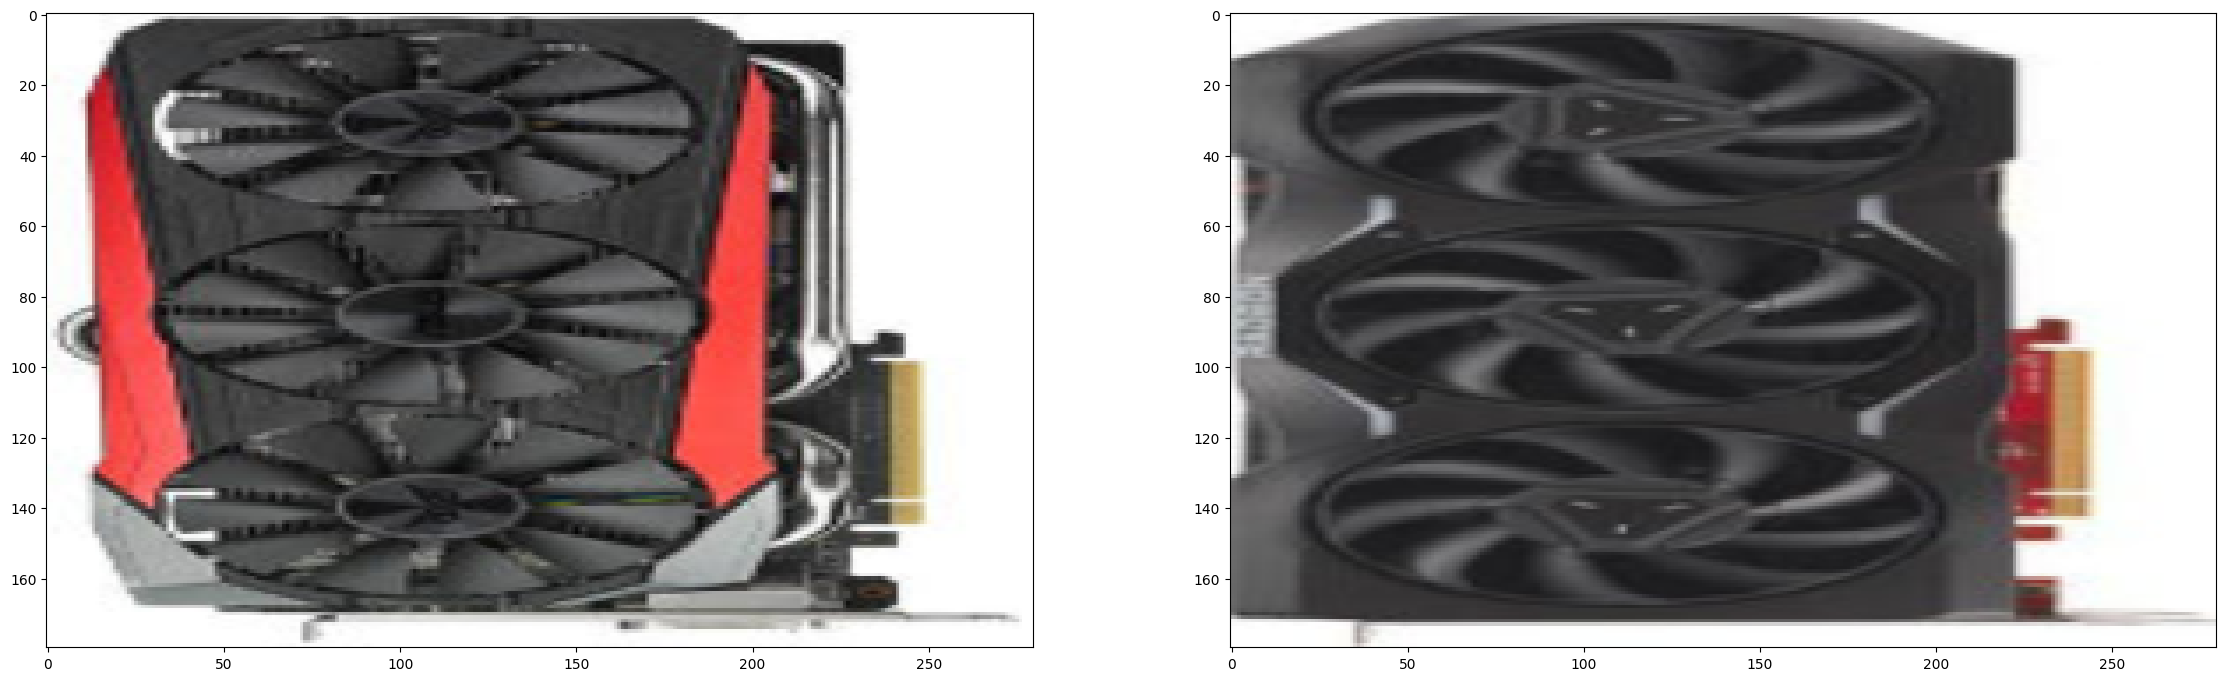

In [11]:
train_data = train_dataloader.dataset
figure = plt.figure(figsize=(28, 28))
figure.add_subplot(1, 2, 1)
plt.imshow(train_data[0][0].squeeze().permute(1, 2, 0))
figure.add_subplot(1, 2, 2)
plt.imshow(test_data[0][0].squeeze().permute(1, 2, 0))
plt.show()

nvidia nvidia nvidia nvidia


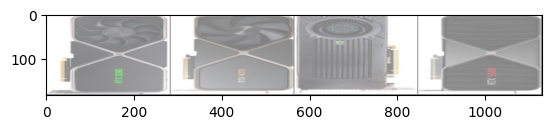

In [ ]:
def show_image(train_loader: DataLoader):
    # get some random training images
    dataiter = iter(train_loader)
    images, labels = next(dataiter)

    img = torchvision.utils.make_grid(images)
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    print(" ".join(f"{classes[labels[j]]:>5}" for j in range(4)))


show_image(train_dataloader)

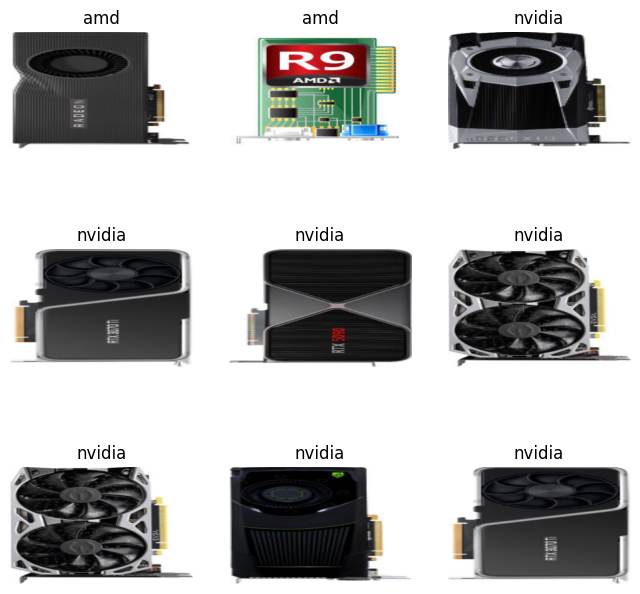

In [12]:
training_data = train_dataloader.dataset

labels_map = {
    0: "amd",
    1: "intel",
    2: "nvidia",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    # PyTorch format: [Channels, Height, Width] → (3, 180, 280)
    # Matplotlib format: [Height, Width, Channels] → (180, 280, 3)
    # Rearrange dimensions from (3, 180, 280) to (180, 280, 3)
    plt.imshow(img.permute(1, 2, 0))
plt.show()